In [2]:
#importing library
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import data_utils as du

In [3]:
#Importing the dataset
reg_path= "../../data/Regression_datasets/hr.csv"
reg_data= pd.read_csv(reg_path)
print(reg_data.head())

   experience  performance  role_level        salary
0           0     2.266659           1  19138.228905
1          20     1.474785           1  52520.174836
2          19     2.878807           4  94270.140793
3           2     1.566725           3  38506.902016
4          19     3.530433           3  85959.434566


In [5]:
#data exploration
du.data_exploration(reg_data)

DATA EXPLORATION
Shape of dataset: 10000 rows, 4 columns

Columns: ['experience', 'performance', 'role_level', 'salary']

Data Types:
 experience       int64
performance    float64
role_level       int64
salary         float64
dtype: object

Missing Values:
 experience     0
performance    0
role_level     0
salary         0
dtype: int64

Statistical Summary:
          experience   performance    role_level         salary
count  10000.000000  10000.000000  10000.000000   10000.000000
mean      14.570600      2.991163      2.997000   74059.666455
std        8.637828      1.147201      1.414352   23051.632392
min        0.000000      1.000109      1.000000   10458.089216
25%        7.000000      2.009630      2.000000   57715.991313
50%       15.000000      2.989070      3.000000   73891.480704
75%       22.000000      3.975798      4.000000   90707.098391
max       29.000000      4.999965      5.000000  136381.420010


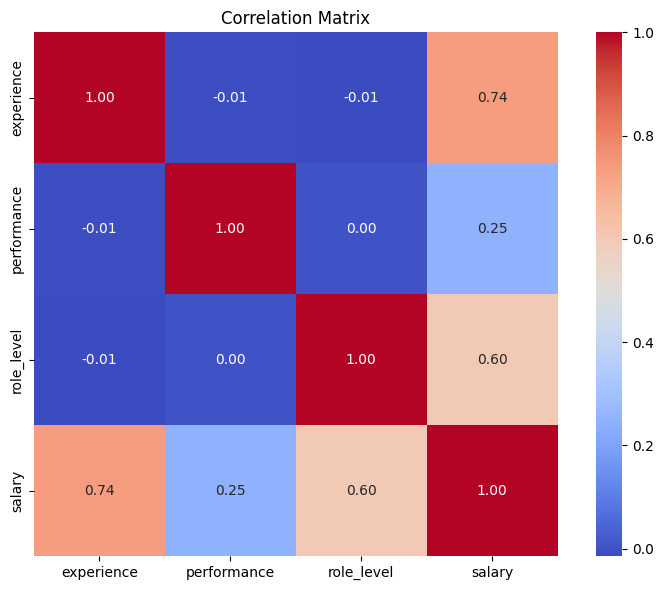

In [6]:
#data visualization
corr = du.get_correlation_matrix(reg_data)
du.plot_correlation_matrix(corr)

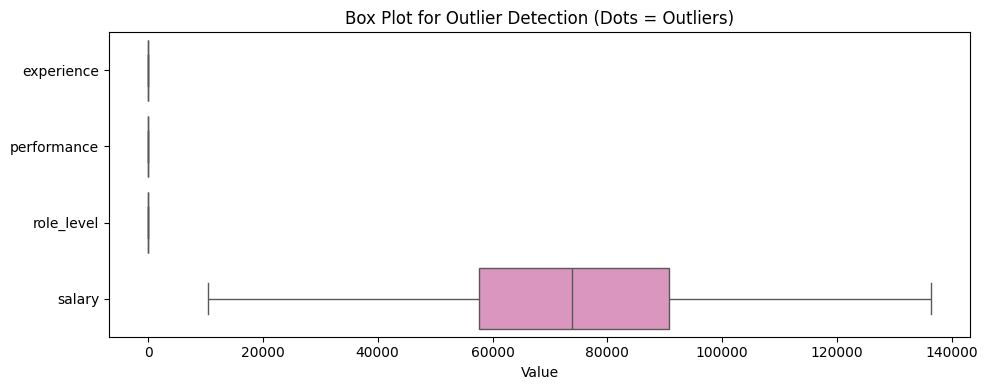

In [7]:
#check for outliers
cols = reg_data.columns
du.plot_boxplots(reg_data, cols)

In [9]:
#linear regression 
X = reg_data.drop('salary', axis=1)
y = reg_data['salary']

In [10]:
model, mse, r2, y_test, y_pred =    du.linear_regression_model(X, y)

Mean Squared Error: 8877884.2800
R-squared: 0.9832


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


In [11]:
du.cross_validation(model, X, y, cv=5)

5-Fold Cross-Validation (r2): [0.98204273 0.9833384  0.98286079 0.98317767 0.98268925]
Average CV score: 0.9828 (± 0.0005)


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: i

array([0.98204273, 0.9833384 , 0.98286079, 0.98317767, 0.98268925])

98% prediction accuracy can able to attain using this data


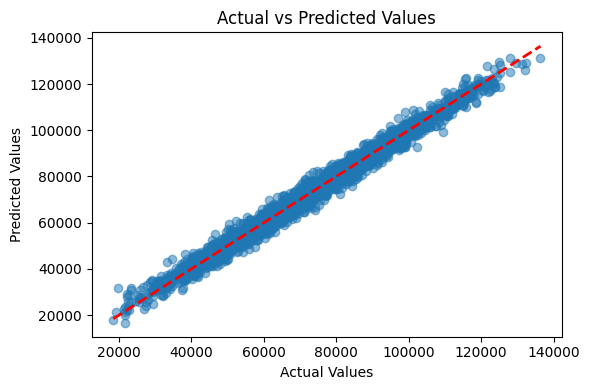

In [12]:
du.plot_actual_vs_predicted(y_test, y_pred)